In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

In [ ]:
df = pd.read_csv("/content/cleaned_repairs_en.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (305649, 12)

Columns:
['id', 'data_provider', 'country', 'product_category_id', 'brand', 'year_of_manufacture', 'product_age', 'repair_status', 'repair_barrier', 'event_date', 'problem', 'problem_en']


,id,data_provider,country,product_category_id,brand,year_of_manufacture,product_age,repair_status,repair_barrier,event_date,problem,problem_en
0,anstiftung_26663,anstiftung,DEU,11,MARLEY,NaN,NaN,End of life,NaN,2025-07-28,wackelkontakt am kopfhörer.,wobble contact on the headphone.
1,anstiftung_26666,anstiftung,DEU,16,DELL,NaN,NaN,End of life,NaN,2025-07-28,kaputt. hardware.,broken. hardware.
2,anstiftung_26770,anstiftung,DEU,40,HILO,NaN,NaN,Repairable,NaN,2025-07-28,Bügeleisen wird nicht mehr heiß. Schalter defekt.,Iron no longer gets hot. Switch broken.
3,anstiftung_26627,anstiftung,DEU,37,THERMOMIX,NaN,NaN,Fixed,NaN,2025-07-28,Herstellung der endgültigen Kipphilfe aus Alth...,Production of the final tipping aid from old w...
4,anstiftung_26664,anstiftung,DEU,16,ACER,NaN,NaN,Fixed,NaN,2025-07-28,kubuntu installiert.,kubuntu installed.


In [ ]:
for col in ["problem_en", "repair_status", "product_category", "brand"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(10))

#This first inspection is important because some repair descriptions may be missing, too short, or recorded in different languages.


--- problem_en ---
problem_en
Unspecified        71779
Not working.         908
No function.         728
Defective.           480
not working.         427
Switch broken.       347
Cable breakage.      338
Wagon contact.       254
Doesn't work.        213
doet het niet.       205
Name: count, dtype: int64

--- repair_status ---
repair_status
Fixed          165144
End of life     77709
Repairable      54049
Unknown          8747
Name: count, dtype: int64

--- brand ---
brand
UNKNOWN    117998
PHILIPS     13451
BOSCH        5963
SONY         5167
HP           3800
SAMSUNG      3594
DYSON        3487
APPLE        3077
MIELE        2817
KENWOOD      2398
Name: count, dtype: int64


In [ ]:
#Before using ML, establish what is already visible in the data.
#This is a basic English-oriented cleaning step. If the dataset contains multiple languages,
#inspect the language information first and consider analyzing English descriptions separately

df = df.copy()

df["problem_en"] = df["problem_en"].fillna("").astype(str)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_problem"] = df["problem_en"].apply(clean_text)

# Remove empty descriptions
df = df[df["clean_problem"].str.len() > 0].copy()

print("Usable problem descriptions:", len(df))
df[["problem_en", "clean_problem"]].head(10)

Usable problem descriptions: 305229


,problem_en,clean_problem
0,wobble contact on the headphone.,wobble contact on the headphone
1,broken. hardware.,broken hardware
2,Iron no longer gets hot. Switch broken.,iron no longer gets hot switch broken
3,Production of the final tipping aid from old w...,production of the final tipping aid from old w...
4,kubuntu installed.,kubuntu installed
5,wrong thread tension.,wrong thread tension
6,No heating. Heating coil defective.,no heating heating coil defective
7,Drive belt ripped.,drive belt ripped
8,No function clock was not aligned.,no function clock was not aligned
9,Don't warm up.,don t warm up


In [ ]:
#This finds common words and two-word phrases.
#It is a useful first look, but high TF-IDF scores are not the same as the number of repair records containing a fault.


vectorizer_words = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000
)

X_words = vectorizer_words.fit_transform(df["clean_problem"])

terms = vectorizer_words.get_feature_names_out()
scores = np.asarray(X_words.sum(axis=0)).ravel()

top_terms = (
    pd.DataFrame({"term": terms, "score": scores})
    .sort_values("score", ascending=False)
    .head(20)
)

print(top_terms)

             term         score
4578  unspecified  71787.411124
2929         niet   5714.669335
4907      working   5399.818121
475        broken   3247.773762
4273       switch   2968.667244
1199         doet   2966.828397
1950          het   2728.638072
2650         meer   2662.604179
2831           ne   2554.843809
1372           en   2407.435549
1033    defective   2371.032477
545         cable   2362.109641
2895          new   2347.418572
271       battery   2313.126799
1013       defect   2267.288862
3420        power   2260.349766
3348         plus   2235.082516
2957    niet meer   2225.921171
1200     doet het   2209.517911
1954     het niet   2129.561263


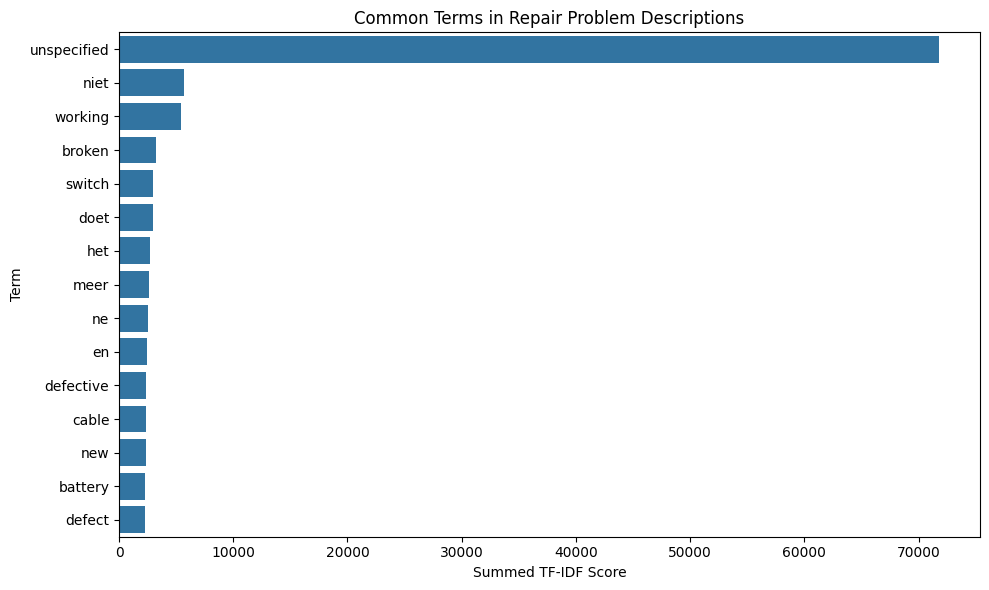

In [ ]:
#chart showing common fault-related terms and a short explanation of what you observed.

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_terms.head(15),
    x="score",
    y="term"
)

plt.title("Common Terms in Repair Problem Descriptions")
plt.xlabel("Summed TF-IDF Score")
plt.ylabel("Term")
plt.tight_layout()
plt.show()

What is TF-IDF?
TF-IDF stands for Term Frequency–Inverse Document Frequency. It converts text into numerical features, giving more importance to words that help distinguish one description from others.

For example, descriptions that mention similar issues may have similar TF-IDF representations. A clustering algorithm can then group descriptions with similar patterns.

In [ ]:
#Each row corresponds to one repair description, and each column corresponds to a text feature.

tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=10000
)

X = tfidf.fit_transform(df["clean_problem"])

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (305229, 10000)


In [ ]:
#K-Means assigns each description to one of five groups.
#The algorithm does not automatically know the technical meaning of those groups;
#you must inspect the descriptions to interpret them.

k = 5

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["fault_cluster"] = kmeans.fit_predict(X)

print(df["fault_cluster"].value_counts().sort_index())

fault_cluster
0     12320
1      6948
2      9026
3    205154
4     71781
Name: count, dtype: int64


In [ ]:
#Read these outputs and give each cluster a human-readable label if the descriptions support one.
#Possible labels might include power-related issues, mechanical problems,or connectivity problems—but use these only
#if your actual cluster examples justify them.


terms = tfidf.get_feature_names_out()

for cluster_id in range(k):
    center = kmeans.cluster_centers_[cluster_id]
    top_indices = center.argsort()[-10:][::-1]
    top_cluster_terms = terms[top_indices]

    print(f"\nCluster {cluster_id}:")
    print(", ".join(top_cluster_terms))

    examples = df.loc[
        df["fault_cluster"] == cluster_id, "problem_en"
    ].head(5)

    print("\nExample descriptions:")
    for example in examples:
        print("-", example)


Cluster 0:
ne, plus, fonctionne, pas, ne fonctionne, fonctionne plus, allume, ne allume, le, allume plus

Example descriptions:
- Fil dessoudé. Ne fonctionne pas. Soudure du fil dessoudé.
- chargeur défectueux. ne démarre plus. chargeur HS. Racheter un chargeur.
- Ne fonctionne pas ,Commutateur mal fixé.
- Inter HS. ne s'allume plus. Inter derouillé.
- Ne charge pas.

Cluster 1:
working, stopped working, stopped, switch working, switch, working working, motor, working anymore, battery, fuse

Example descriptions:
- It's not working anymore.
- It's not working properly.
- It's not working anymore; a wrong battery has been used.
- Lights up, but engine's not working.
- It's not working anymore.

Cluster 2:
doet het, het, het niet, doet, niet, niet meer, meer, defect, defect doet, schakelaar

Example descriptions:
- Niet gevonden. Doet het niet.
- Aan/uit schakelaar stuk. Doet het niet. Schakelaar niet repareren.
- Snoer stuk. Doet het niet meer. Snoer ingekort en opnieuw gemonteerd.
- V

In [ ]:
#Check the quality of your clusters

results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    # Sample rows to keep computation manageable
    sample_size = min(2000, X.shape[0])

    score = silhouette_score(
        X,
        labels,
        sample_size=sample_size,
        random_state=42
    )

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": score
    })

results_df = pd.DataFrame(results)
print(results_df)

   k        inertia  silhouette_score
0  2  230434.877320          0.237173
1  3  228315.858029          0.238569
2  4  227139.288359          0.238598
3  5  225521.200507          0.240965
4  6  224587.772239          0.241502
5  7  223648.879603          0.242302
6  8  222956.463891          0.242648


In [ ]:
#task connecting NLP work to business decisions.
if "repair_status" in df.columns:
    print(df["repair_status"].value_counts(dropna=False))

repair_status
Fixed          164961
End of life     77543
Repairable      53995
Unknown          8730
Name: count, dtype: int64


repair_status  End of life  Fixed  Repairable  Unknown
fault_cluster                                         
0                    29.42  46.19       23.94     0.45
1                    32.74  45.11       17.60     4.55
2                    37.43  51.19       11.38     0.01
3                    23.44  54.27       20.76     1.52
4                    28.10  55.97        8.64     7.29


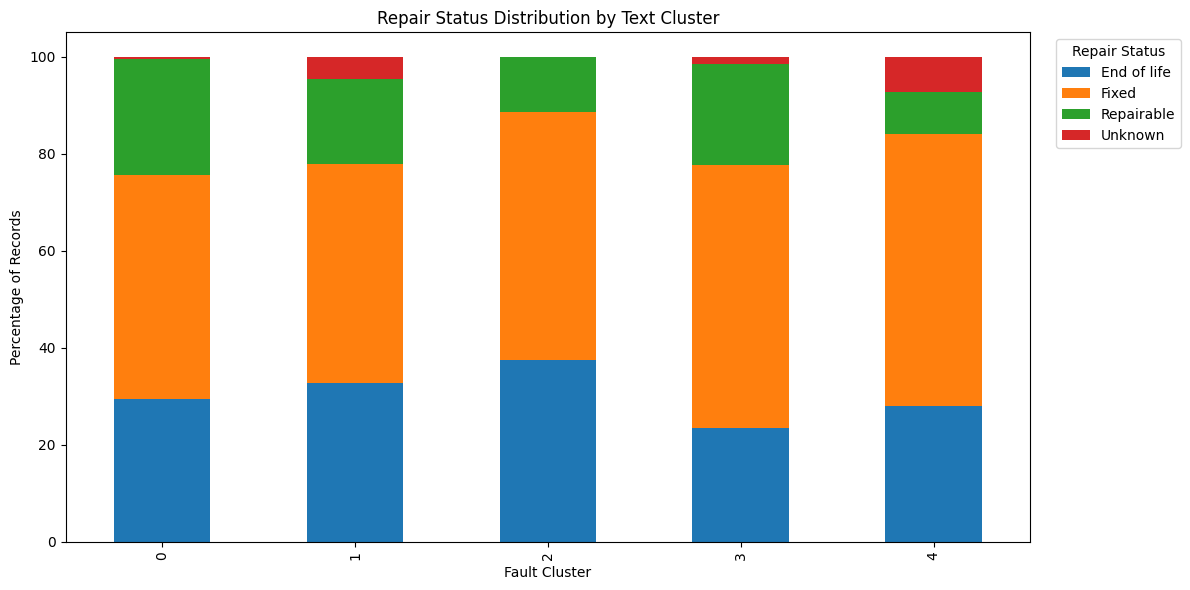

In [ ]:
#This chart will help you see whether the recorded repair statuses vary across the clusters.
#For example, if a cluster has a higher proportion of unsuccessful repair attempts,
#you could investigate the descriptions and recorded repair barriers in that cluster.


if "repair_status" in df.columns:
    outcome_table = pd.crosstab(
        df["fault_cluster"],
        df["repair_status"],
        normalize="index"
    ) * 100

    print(outcome_table.round(2))

    outcome_table.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )

    plt.title("Repair Status Distribution by Text Cluster")
    plt.xlabel("Fault Cluster")
    plt.ylabel("Percentage of Records")
    plt.legend(title="Repair Status", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

In [ ]:
df.to_csv("member3_clustered_repairs.csv", index=False)

In [ ]:
cluster_summary = (
    df.groupby("fault_cluster")
      .agg(
          record_count=("problem", "size"),
          unique_brands=("brand", "nunique")
      )
      .reset_index()
)

cluster_summary.to_csv(
    "member3_cluster_summary.csv",
    index=False
)